# Sri Lankan Telecom Churn — Local Project Run

This notebook runs from the project folder in VS Code/Jupyter. It uses the existing processed train/test data, saved models, and project result folders. It does not require Google Colab, Google Drive, or a Kaggle download.

**Setup:** select the project Python environment and run `python -m pip install -r requirements.txt` from the project root once. Then run these cells from top to bottom.

The raw source CSVs are not included in this project folder, so this notebook starts from the supplied processed data and evaluates the supplied trained models.

In [1]:
from pathlib import Path
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

# Find the project root whether Jupyter starts in the root or notebooks/.
current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "data" / "processed" / "train_processed.parquet").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/processed/train_processed.parquet above the current "
        f"working directory: {current_dir}. Open this notebook from the project folder."
    )

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in (METRICS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Processed data: {DATA_DIR}")
print(f"Models: {MODEL_DIR}")
print(f"Results: {RESULTS_DIR}")

Project root: D:\semester 7\ML\assignmnet 01\Sri_Lankan_Telecom_Churn_Submission
Processed data: D:\semester 7\ML\assignmnet 01\Sri_Lankan_Telecom_Churn_Submission\data\processed
Models: D:\semester 7\ML\assignmnet 01\Sri_Lankan_Telecom_Churn_Submission\models
Results: D:\semester 7\ML\assignmnet 01\Sri_Lankan_Telecom_Churn_Submission\results


In [2]:
required_files = [
    DATA_DIR / "train_processed.parquet",
    DATA_DIR / "test_processed.parquet",
    DATA_DIR / "X_test.parquet",
    DATA_DIR / "y_train.csv",
    DATA_DIR / "y_test.csv",
    MODEL_DIR / "feature_names.json",
    MODEL_DIR / "model_metadata.json",
    MODEL_DIR / "random_forest.joblib",
    MODEL_DIR / "adaboost.joblib",
    MODEL_DIR / "gradient_boosting.joblib",
    MODEL_DIR / "stacking.joblib",
]
missing_files = [path for path in required_files if not path.is_file()]
if missing_files:
    missing_list = "\n".join(str(path.relative_to(PROJECT_ROOT)) for path in missing_files)
    raise FileNotFoundError(f"Required project files are missing:\n{missing_list}")

with (MODEL_DIR / "feature_names.json").open(encoding="utf-8") as file:
    feature_names = json.load(file)
with (MODEL_DIR / "model_metadata.json").open(encoding="utf-8") as file:
    model_metadata = json.load(file)

train_processed = pd.read_parquet(DATA_DIR / "train_processed.parquet")
test_processed = pd.read_parquet(DATA_DIR / "test_processed.parquet")
X_test = pd.read_parquet(DATA_DIR / "X_test.parquet")
y_train = pd.read_csv(DATA_DIR / "y_train.csv", dtype={"customer_id": "string"})
y_test = pd.read_csv(DATA_DIR / "y_test.csv", dtype={"customer_id": "string"})

print(f"Training data: {train_processed.shape}")
print(f"Testing data:  {test_processed.shape}")
print(f"Test features: {X_test.shape}")
print(f"Feature count: {len(feature_names)}")
print(f"Metadata: {model_metadata['project']}")
display(train_processed.head(3))
display(test_processed.head(3))

Training data: (52004, 158)
Testing data:  (13001, 158)
Test features: (13001, 157)
Feature count: 156
Metadata: Sri Lankan Telecom Customer Churn Prediction


,customer_id,churn,usage_app_facebook_daily_total_28d,usage_app_helakuru_daily_total_28d,usage_app_other_total_28d,usage_app_tiktok_daily_total_28d,usage_app_whatsapp_daily_total_28d,usage_app_youtube_daily_total_28d,usage_pack_data_total_28d,usage_pack_vas_total_28d,...,usage_app_other_week_4,usage_app_tiktok_daily_week_4,usage_app_whatsapp_daily_week_4,usage_app_youtube_daily_week_4,usage_pack_data_week_4,usage_pack_vas_week_4,usage_voice_d2d_incoming_week_4,usage_voice_d2d_outgoing_week_4,usage_voice_d2nd_outgoing_week_4,usage_voice_nd2d_incoming_week_4
0,a8cfed4379972f41e730a31a5c500e9ed2592374761b09...,0,2881.080078,90.549995,2527.750244,1160.399902,394.970032,998.610046,2383.400146,521.569946,...,1052.479980,360.529999,39.150002,0.0,772.359985,133.089996,76.509995,221.720001,177.259995,83.139999
1,d231e6c6dfd09290c16f640288edcd0ec5de526681c5e8...,0,3936.450195,138.289993,1890.300049,1562.929932,417.760010,1781.699829,723.490051,741.570007,...,581.130005,565.929993,155.589996,0.0,77.050003,64.690002,143.220001,191.699982,212.320007,253.490005
2,787d994dc6e133f5711414ac7959d3263af560f19dd634...,0,3504.199951,197.210007,2993.850098,2084.260010,374.879974,2492.699951,2593.770020,445.300018,...,26.809999,124.830002,74.830002,0.0,1084.070068,44.809998,56.770000,13.969999,351.130005,8.350000


,customer_id,churn,usage_app_facebook_daily_total_28d,usage_app_helakuru_daily_total_28d,usage_app_other_total_28d,usage_app_tiktok_daily_total_28d,usage_app_whatsapp_daily_total_28d,usage_app_youtube_daily_total_28d,usage_pack_data_total_28d,usage_pack_vas_total_28d,...,usage_app_other_week_4,usage_app_tiktok_daily_week_4,usage_app_whatsapp_daily_week_4,usage_app_youtube_daily_week_4,usage_pack_data_week_4,usage_pack_vas_week_4,usage_voice_d2d_incoming_week_4,usage_voice_d2d_outgoing_week_4,usage_voice_d2nd_outgoing_week_4,usage_voice_nd2d_incoming_week_4
0,e4b72c1c45b982f8b39f4cab732c433b24d03d52e5a0b1...,1,1189.199951,150.070007,2376.780029,559.890015,159.500000,1275.400024,1793.430054,302.469971,...,524.450012,0.000000,16.200001,0.000000,974.529968,0.0,17.389999,27.360001,0.000000,0.000000
1,b9996abf8720c9c554b78617f27827c18e597b378227d2...,0,2058.169922,215.439987,2625.819824,747.630005,585.610046,2442.200195,2016.010010,440.940033,...,394.910004,61.020000,65.650002,940.219971,602.910034,0.0,289.329987,0.000000,96.840004,8.560000
2,18a737f17b32318ed4a99a0a03dbc5d9b60181cf91a3d8...,1,1182.619995,108.200012,5366.890137,720.700012,134.029999,1339.540039,2492.560059,390.640015,...,835.789978,76.479996,5.510000,0.000000,0.000000,0.0,18.450001,12.390000,13.370000,279.300018


In [3]:
required_columns = {"customer_id", "churn"}
for name, frame in (("train_processed", train_processed), ("test_processed", test_processed)):
    missing = required_columns.difference(frame.columns)
    if missing:
        raise ValueError(f"{name} is missing required columns: {sorted(missing)}")

missing_features = [name for name in feature_names if name not in X_test.columns]
if missing_features:
    raise ValueError(f"X_test is missing model features: {missing_features[:10]}")
if X_test[feature_names].isna().any().any():
    raise ValueError("X_test contains missing values in model features.")

X_test["customer_id"] = X_test["customer_id"].astype("string")
if len(X_test) != len(y_test):
    raise ValueError(f"Test feature/label row counts differ: {len(X_test)} vs {len(y_test)}")
if not X_test["customer_id"].reset_index(drop=True).equals(
    y_test["customer_id"].reset_index(drop=True)
):
    raise ValueError("Test customer IDs in X_test.parquet and y_test.csv are not aligned.")
if not set(y_test["churn"].unique()).issubset({0, 1}):
    raise ValueError("Expected binary churn labels 0 and 1 in y_test.csv.")

print("Feature names and test labels are aligned.")
print("Training churn distribution:")
display(y_train["churn"].value_counts().sort_index().rename_axis("churn").to_frame("count"))
print("Testing churn distribution:")
display(y_test["churn"].value_counts().sort_index().rename_axis("churn").to_frame("count"))

Feature names and test labels are aligned.
Training churn distribution:


,count
churn,
0,39982
1,12022


Testing churn distribution:


,count
churn,
0,10023
1,2978


In [4]:
model_files = {
    "Random Forest": "random_forest.joblib",
    "AdaBoost": "adaboost.joblib",
    "Gradient Boosting": "gradient_boosting.joblib",
    "Stacking": "stacking.joblib",
}
y_true = y_test["churn"].to_numpy()
X_test_model = X_test[feature_names]
model_results = []
predictions = {}
probabilities = {}
loaded_models = {}
classification_reports = {}

for model_name, filename in model_files.items():
    model_path = MODEL_DIR / filename
    model = joblib.load(model_path)
    loaded_models[model_name] = model

    started_at = time.perf_counter()
    y_pred = model.predict(X_test_model)
    if not hasattr(model, "predict_proba"):
        raise TypeError(f"{model_name} does not support predict_proba().")
    class_indices = np.flatnonzero(np.asarray(model.classes_) == 1)
    if len(class_indices) != 1:
        raise ValueError(f"{model_name} has no unique positive class (1).")
    y_prob = model.predict_proba(X_test_model)[:, class_indices[0]]
    prediction_seconds = time.perf_counter() - started_at

    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob
    model_results.append(
        {
            "Model": model_name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1 Score": f1_score(y_true, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, y_prob),
            "Prediction Time (sec)": prediction_seconds,
        }
    )
    classification_reports[model_name] = classification_report(
        y_true,
        y_pred,
        target_names=["Not Churn", "Churn"],
        output_dict=True,
        zero_division=0,
    )
    print(f"Evaluated {model_name}: {model_path.relative_to(PROJECT_ROOT)}")

comparison = pd.DataFrame(model_results).sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)
display(comparison.style.format({
    "Accuracy": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1 Score": "{:.4f}",
    "ROC-AUC": "{:.4f}",
    "Prediction Time (sec)": "{:.2f}",
}))

Evaluated Random Forest: models\random_forest.joblib
Evaluated AdaBoost: models\adaboost.joblib
Evaluated Gradient Boosting: models\gradient_boosting.joblib
Evaluated Stacking: models\stacking.joblib


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Prediction Time (sec)
0,Stacking,0.9606,0.8877,0.9480,0.9169,0.9928,0.67
1,Gradient Boosting,0.9596,0.9705,0.8496,0.9060,0.9924,0.07
2,AdaBoost,0.9564,0.9490,0.8556,0.8999,0.9912,0.33
3,Random Forest,0.9515,0.9380,0.8439,0.8885,0.9877,0.24


In [5]:
# Keep the original result files intact; local re-evaluation outputs are clearly named.
comparison_path = METRICS_DIR / "local_test_model_comparison.csv"
reports_path = METRICS_DIR / "local_classification_reports.json"
comparison.to_csv(comparison_path, index=False)
with reports_path.open("w", encoding="utf-8") as file:
    json.dump(classification_reports, file, indent=2)

customer_ids = X_test["customer_id"].astype("string").to_numpy()
for model_name, y_pred in predictions.items():
    safe_name = model_name.lower().replace(" ", "_")
    prediction_path = RESULTS_DIR / f"local_{safe_name}_test_predictions.csv"
    pd.DataFrame(
        {
            "customer_id": customer_ids,
            "actual_churn": y_true,
            "predicted_churn": y_pred,
            "churn_probability": probabilities[model_name],
        }
    ).to_csv(prediction_path, index=False)
    print(f"Saved {prediction_path.relative_to(PROJECT_ROOT)}")

print(f"Saved {comparison_path.relative_to(PROJECT_ROOT)}")
print(f"Saved {reports_path.relative_to(PROJECT_ROOT)}")

Saved results\local_random_forest_test_predictions.csv
Saved results\local_adaboost_test_predictions.csv
Saved results\local_gradient_boosting_test_predictions.csv
Saved results\local_stacking_test_predictions.csv
Saved results\metrics\local_test_model_comparison.csv
Saved results\metrics\local_classification_reports.json


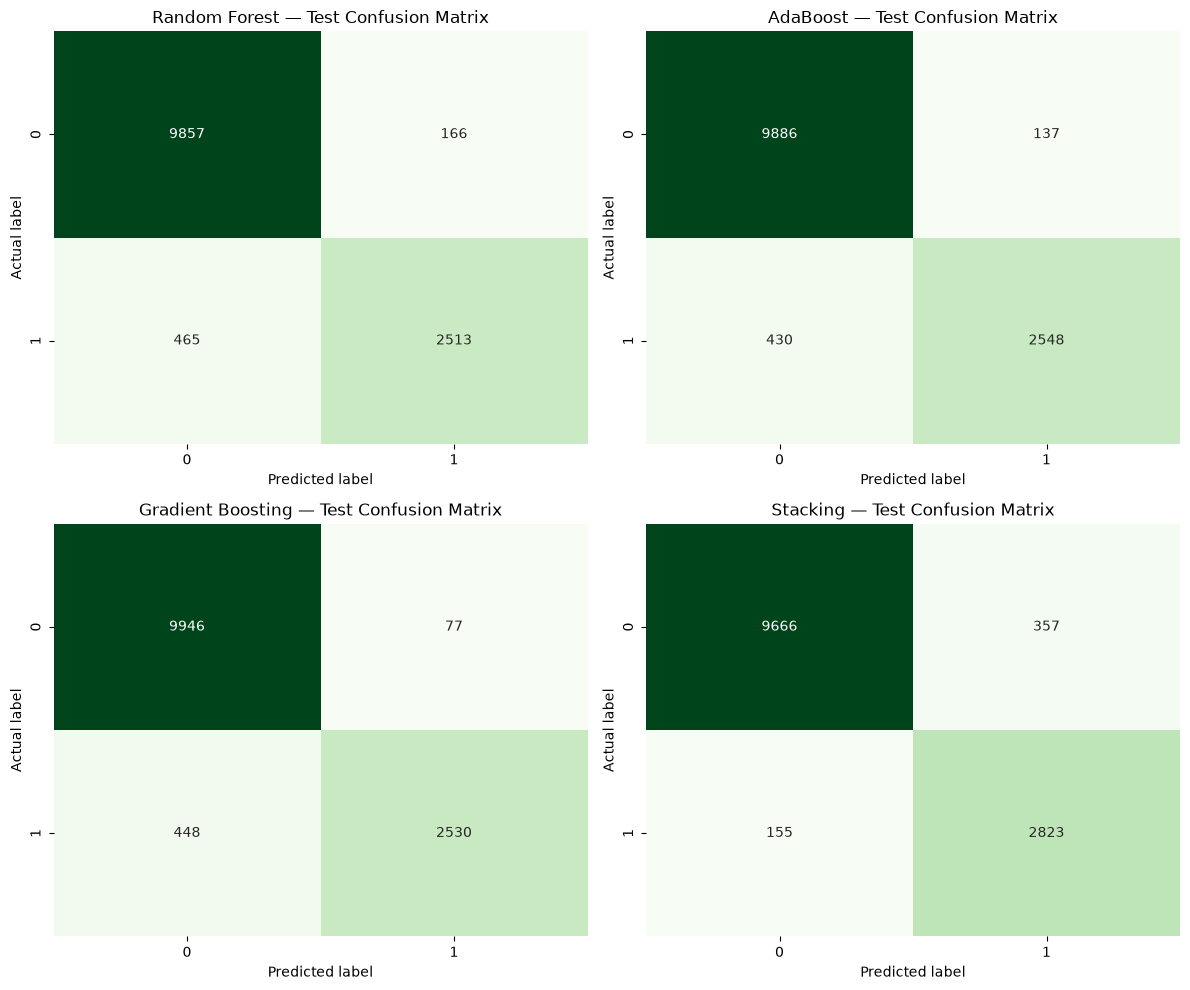

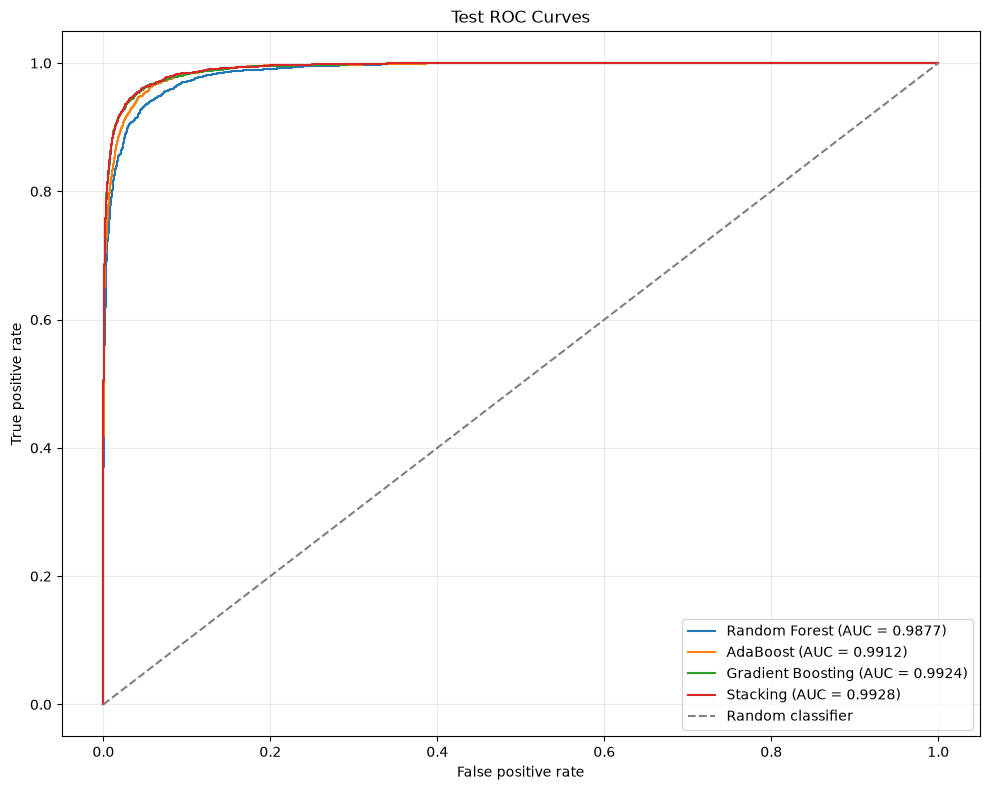

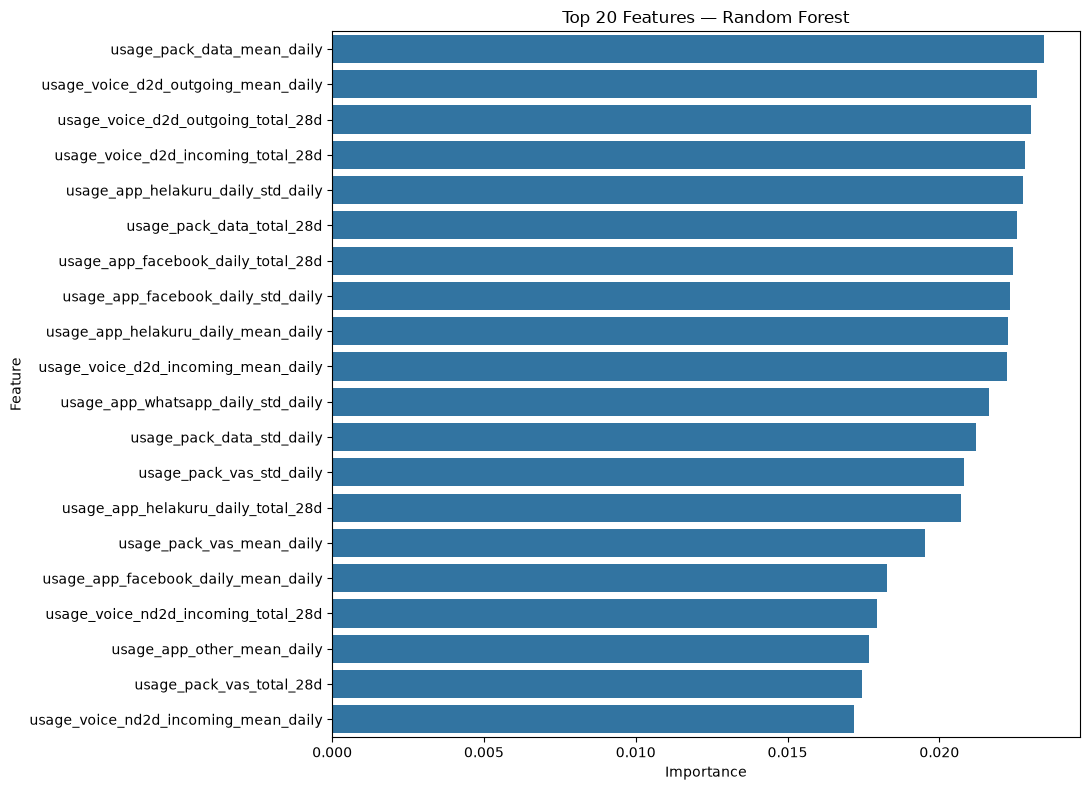

,Feature,Importance
18,usage_pack_data_mean_daily,0.023461
21,usage_voice_d2d_outgoing_mean_daily,0.023227
9,usage_voice_d2d_outgoing_total_28d,0.023017
8,usage_voice_d2d_incoming_total_28d,0.022812
25,usage_app_helakuru_daily_std_daily,0.022745
6,usage_pack_data_total_28d,0.022548
0,usage_app_facebook_daily_total_28d,0.022427
24,usage_app_facebook_daily_std_daily,0.022334
13,usage_app_helakuru_daily_mean_daily,0.022256
20,usage_voice_d2d_incoming_mean_daily,0.022229


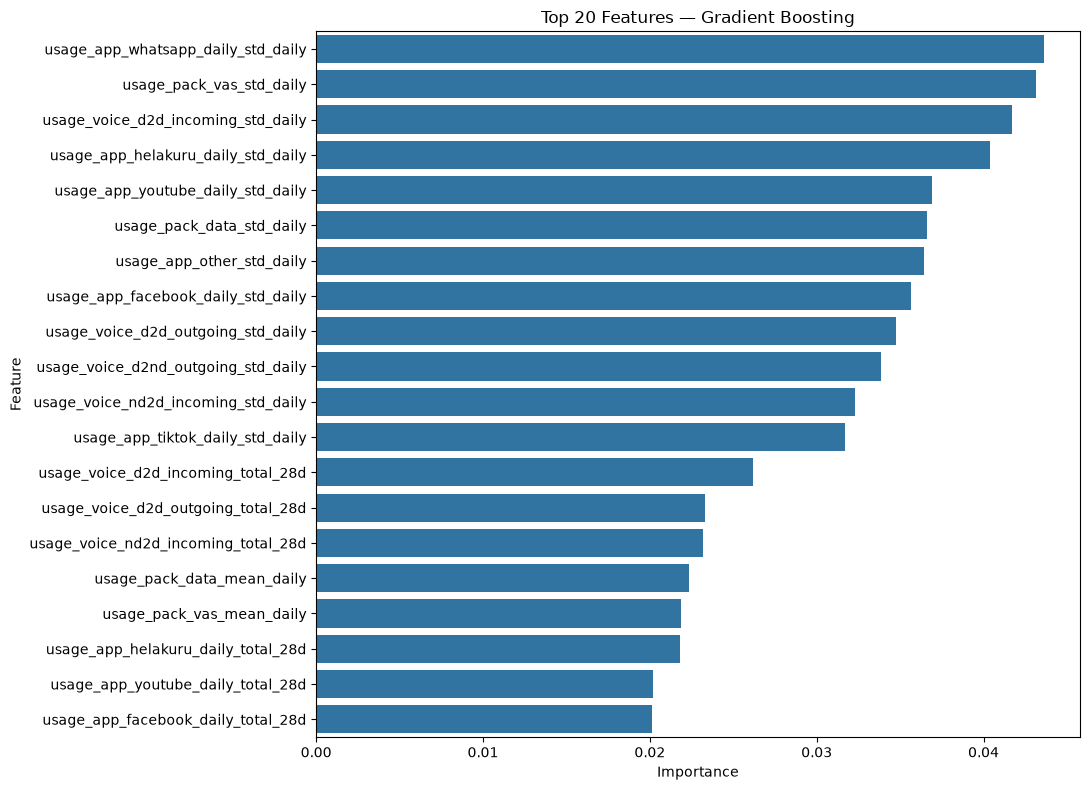

,Feature,Importance
28,usage_app_whatsapp_daily_std_daily,0.043601
31,usage_pack_vas_std_daily,0.043141
32,usage_voice_d2d_incoming_std_daily,0.041691
25,usage_app_helakuru_daily_std_daily,0.040402
29,usage_app_youtube_daily_std_daily,0.036911
30,usage_pack_data_std_daily,0.036632
26,usage_app_other_std_daily,0.036405
24,usage_app_facebook_daily_std_daily,0.035623
33,usage_voice_d2d_outgoing_std_daily,0.034745
34,usage_voice_d2nd_outgoing_std_daily,0.033832


,Feature,Importance
34,usage_voice_d2nd_outgoing_std_daily,0.053681
26,usage_app_other_std_daily,0.047372
30,usage_pack_data_std_daily,0.043339
24,usage_app_facebook_daily_std_daily,0.040627
28,usage_app_whatsapp_daily_std_daily,0.040168
33,usage_voice_d2d_outgoing_std_daily,0.035924
29,usage_app_youtube_daily_std_daily,0.035041
27,usage_app_tiktok_daily_std_daily,0.032225
22,usage_voice_d2nd_outgoing_mean_daily,0.031925
32,usage_voice_d2d_incoming_std_daily,0.029925


Saved local figures to D:\semester 7\ML\assignmnet 01\Sri_Lankan_Telecom_Churn_Submission\results\figures


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, model_name in zip(axes.flat, model_files):
    matrix = confusion_matrix(y_true, predictions[model_name], labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Greens", cbar=False, ax=ax)
    ax.set_title(f"{model_name} — Test Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
fig.tight_layout()
confusion_path = FIGURES_DIR / "local_final_test_confusion_matrices.png"
fig.savefig(confusion_path, dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
for model_name, y_prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_value = roc_auc_score(y_true, y_prob)
    ax.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_value:.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random classifier")
ax.set(title="Test ROC Curves", xlabel="False positive rate", ylabel="True positive rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
fig.tight_layout()
roc_path = FIGURES_DIR / "local_final_test_roc_curves.png"
fig.savefig(roc_path, dpi=150, bbox_inches="tight")
plt.show()

for model_name in ("Random Forest", "Gradient Boosting", "AdaBoost"):
    model = loaded_models[model_name]
    if not hasattr(model, "feature_importances_"):
        print(f"Skipping feature importance for {model_name}: not supported.")
        continue
    importance = pd.DataFrame(
        {"Feature": feature_names, "Importance": model.feature_importances_}
    ).sort_values("Importance", ascending=False)
    safe_name = model_name.lower().replace(" ", "_")
    importance.to_csv(METRICS_DIR / f"local_{safe_name}_feature_importance.csv", index=False)
    if model_name in ("Random Forest", "Gradient Boosting"):
        fig, ax = plt.subplots(figsize=(11, 8))
        sns.barplot(data=importance.head(20), x="Importance", y="Feature", ax=ax)
        ax.set_title(f"Top 20 Features — {model_name}")
        fig.tight_layout()
        fig.savefig(FIGURES_DIR / f"local_{safe_name}_feature_importance.png", dpi=150)
        plt.show()
    display(importance.head(10))

print(f"Saved local figures to {FIGURES_DIR}")

In [7]:
local_outputs = [
    comparison_path,
    reports_path,
    confusion_path,
    roc_path,
    *[RESULTS_DIR / f"local_{name.lower().replace(' ', '_')}_test_predictions.csv" for name in model_files],
]
missing_outputs = [path for path in local_outputs if not path.is_file()]
if missing_outputs:
    raise FileNotFoundError(f"Expected outputs were not created: {missing_outputs}")

print("Local run completed successfully.")
print(f"Project root: {PROJECT_ROOT}")
for path in local_outputs:
    print(f"{path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

Local run completed successfully.
Project root: D:\semester 7\ML\assignmnet 01\Sri_Lankan_Telecom_Churn_Submission
results\metrics\local_test_model_comparison.csv (582 bytes)
results\metrics\local_classification_reports.json (2,962 bytes)
results\figures\local_final_test_confusion_matrices.png (79,658 bytes)
results\figures\local_final_test_roc_curves.png (84,784 bytes)
results\local_random_forest_test_predictions.csv (1,160,014 bytes)
results\local_adaboost_test_predictions.csv (1,160,638 bytes)
results\local_gradient_boosting_test_predictions.csv (1,169,980 bytes)
results\local_stacking_test_predictions.csv (1,171,775 bytes)
